# Reconciliation checks
Short notebook: scores the SQL pipeline against the planted breaks, shows the control totals, and draws 4 control charts. **SIMULATED transactions, REAL daily prices.** Run `python src/generate_sim.py` then `python src/run_sql.py` first.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
con = duckdb.connect(str(ROOT / 'data' / 'recon.duckdb'), read_only=True)
q = lambda sql: con.execute(sql).df()
BLUE, GREY, RED = '#2A78D6', '#898781', '#D03B3B'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Did the pipeline find the planted breaks?
`recall` = share of planted breaks found; `precision` = share of found breaks that were really planted.

In [2]:
q('SELECT * FROM validation')

,issue_type,planted,found,true_positives,missed,false_alarms,recall,precision,status_ok
0,address_reuse,513,513,513,0,0,1.0000,1.0,1.0
1,late_payment,3362,3362,3362,0,0,1.0000,1.0,1.0
2,ledger_duplicate,2238,2238,2238,0,0,1.0000,1.0,1.0
3,missing_partner_fee,1495,1381,1381,114,0,0.9237,1.0,1.0
4,overpayment,1736,1736,1736,0,0,1.0000,1.0,1.0
5,premature_credit,659,659,659,0,0,1.0000,1.0,1.0
6,rate_gap,1709,1709,1709,0,0,1.0000,1.0,1.0
7,timezone_cutoff,1910,1910,1910,0,0,1.0000,1.0,1.0
8,underpayment,4490,4490,4490,0,0,1.0000,1.0,1.0
9,wrong_network,625,625,625,0,0,1.0000,1.0,1.0


## 2. Do all control totals tie out?
`residual` must be 0 on every line.

In [3]:
q('SELECT control, unit, round(difference, 2) AS difference, round(explained, 2) AS explained, residual, result FROM controls')

,control,unit,difference,explained,residual,result
0,C1 Chain receipts vs ledger deposits - BNB,BNB,4.06,4.06,-0.0,PASS
1,C1 Chain receipts vs ledger deposits - BTC,BTC,0.08,0.08,0.0,PASS
2,C1 Chain receipts vs ledger deposits - ETH,ETH,1.30,1.30,-0.0,PASS
3,C1 Chain receipts vs ledger deposits - LTC,LTC,-18.04,-18.04,0.0,PASS
4,C1 Chain receipts vs ledger deposits - SOL,SOL,5.63,5.63,-0.0,PASS
5,C1 Chain receipts vs ledger deposits - TRX,TRX,-4883.63,-4883.63,0.0,PASS
6,C1 Chain receipts vs ledger deposits - USDC,USDC,-2859.83,-2859.83,0.0,PASS
7,C1 Chain receipts vs ledger deposits - USDT,USDT,11763.53,11763.53,-0.0,PASS
8,C2 Partner EUR vs ledger conversions,EUR,-107173.41,-107173.41,-0.0,PASS
9,C2b Rate gaps: posted fx_adjustments + open gaps,EUR,-955.77,-955.77,0.0,PASS


## 3. Control charts

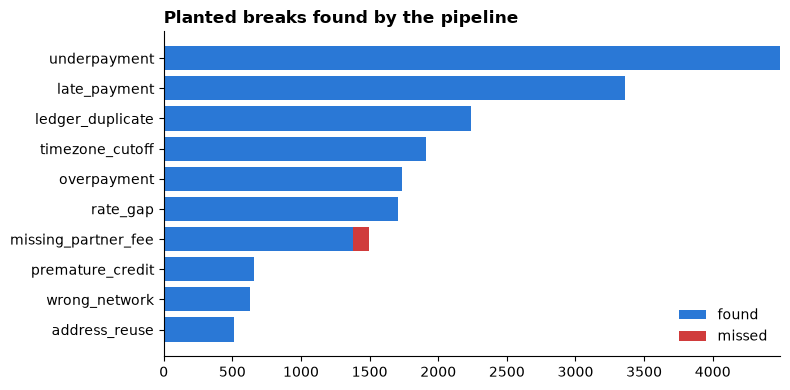

In [4]:
v = q("SELECT issue_type, planted, true_positives, missed FROM validation WHERE issue_type IS NOT NULL ORDER BY planted")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(v.issue_type, v.true_positives, color=BLUE, label='found')
ax.barh(v.issue_type, v.missed, left=v.true_positives, color=RED, label='missed')
ax.set_title('Planted breaks found by the pipeline', loc='left', fontweight='bold'); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(ROOT / 'docs' / 'check_validation.png', dpi=150)

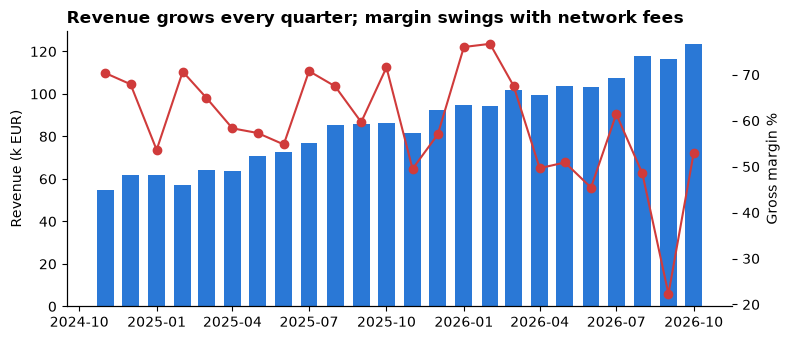

In [5]:
k = q('SELECT month, revenue_eur, gross_margin_pct FROM kpis_monthly')
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(k.month, k.revenue_eur / 1e3, width=20, color=BLUE); ax.set_ylabel('Revenue (k EUR)')
ax2 = ax.twinx(); ax2.plot(k.month, k.gross_margin_pct * 100, color=RED, marker='o'); ax2.set_ylabel('Gross margin %')
ax.set_title('Revenue grows every quarter; margin swings with network fees', loc='left', fontweight='bold')
fig.tight_layout(); fig.savefig(ROOT / 'docs' / 'check_revenue_margin.png', dpi=150)

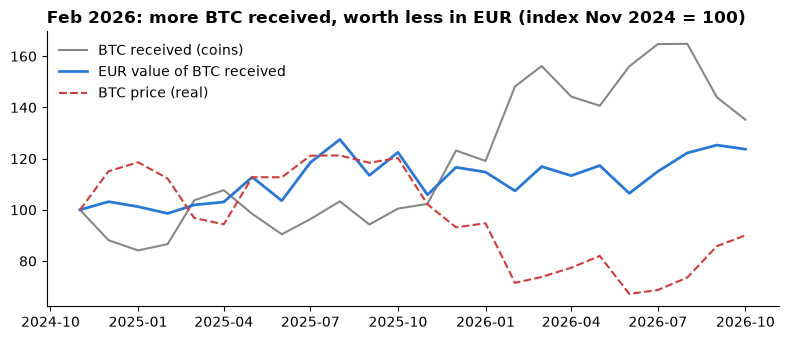

In [6]:
b = q("""SELECT date_trunc('month', f.date) AS month, sum(f.volume_crypto) AS btc_received,
              sum(f.volume_eur) AS eur_value, avg(p.price_eur) AS btc_price
       FROM fact_daily_currency f JOIN price_eur p ON p.d = f.date AND p.currency = 'BTC'
       WHERE f.currency = 'BTC' GROUP BY 1 ORDER BY 1""")
b = b.set_index('month'); idx = b / b.iloc[0] * 100
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(idx.index, idx.btc_received, color=GREY, label='BTC received (coins)')
ax.plot(idx.index, idx.eur_value, color=BLUE, lw=2, label='EUR value of BTC received')
ax.plot(idx.index, idx.btc_price, color=RED, ls='--', label='BTC price (real)')
ax.set_title('Feb 2026: more BTC received, worth less in EUR (index Nov 2024 = 100)', loc='left', fontweight='bold')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(ROOT / 'docs' / 'check_btc_feb2026.png', dpi=150)

,age_bucket,breaks,eur
0,0-2 d,55,9420.89
1,3-7 d,73,7068.98
2,8-30 d,101,9888.43
3,> 30 d,1258,150557.62


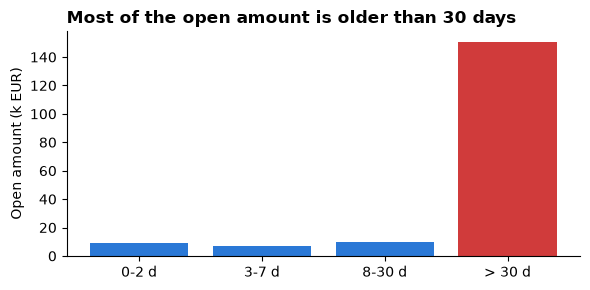

In [7]:
a = q("""SELECT age_bucket, count(*) AS breaks, sum(amount_at_stake_eur) AS eur FROM breaks
       WHERE status = 'open' GROUP BY 1 ORDER BY CASE age_bucket WHEN '0-2 d' THEN 1 WHEN '3-7 d' THEN 2
       WHEN '8-30 d' THEN 3 ELSE 4 END""")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(a.age_bucket, a.eur / 1e3, color=[BLUE, BLUE, BLUE, RED])
ax.set_ylabel('Open amount (k EUR)')
ax.set_title('Most of the open amount is older than 30 days', loc='left', fontweight='bold')
fig.tight_layout(); fig.savefig(ROOT / 'docs' / 'check_break_ageing.png', dpi=150); a

## 4. Files for Tableau
Written by `src/run_sql.py` to `data/output/` (CSV).

In [8]:
pd.DataFrame([(f.name, sum(1 for _ in open(f, encoding='utf-8')) - 1) for f in sorted((ROOT / 'data' / 'output').glob('*.csv'))],
             columns=['file', 'rows'])

,file,rows
0,breaks.csv,18623
1,cohorts.csv,324
2,controls.csv,16
3,dim_merchants.csv,1500
4,fact_daily_currency.csv,8288
5,fact_monthly.csv,128803
6,kpis_monthly.csv,24
7,prices_daily.csv,5840
8,recon_daily.csv,2193
9,revenue_bridge.csv,299
